# 1. Text dataset preparation

In [1]:
import pandas as pd

df = pd.read_csv(
    "data.csv",
    sep="|",
    header=None,
    names=["path", "speaker", "text"],
    encoding="utf-8",
)
df.head()

,path,speaker,text
0,wavs/D/F2/0701-F2D/0701-F2D-0001.wav,7,džiugios naujienos iš čekijos
1,wavs/D/F2/0701-F2D/0701-F2D-0002.wav,7,sėkmė lydėjo mūsų mokyklos mokinį vilių
2,wavs/D/F2/0701-F2D/0701-F2D-0003.wav,7,čekijos sostinėje prahoje vykusiame tarptautin...
3,wavs/D/F2/0701-F2D/0701-F2D-0004.wav,7,festivalyje laimėta pirmoji vieta
4,wavs/D/F2/0701-F2D/0701-F2D-0005.wav,7,didžiuojamės ir džiaugiamės įspūdingu pasiekim...


In [2]:
df["path"] = df["path"].str.split("/").str[1]
df = df.rename(columns={"path": "emotion"})
df = df[['text', 'emotion']]

emotion_map = {
    "D": "Joy",
    "L": "Sadness",
    "N": "Surprise",
    "P": "Anger",
    "Z": "Neutral",
}

df["emotion"] = df["emotion"].map(emotion_map)

df

,text,emotion
0,džiugios naujienos iš čekijos,Joy
1,sėkmė lydėjo mūsų mokyklos mokinį vilių,Joy
2,čekijos sostinėje prahoje vykusiame tarptautin...,Joy
3,festivalyje laimėta pirmoji vieta,Joy
4,didžiuojamės ir džiaugiamės įspūdingu pasiekim...,Joy
...,...,...
349691,laisvas minčių srautas,Neutral
349692,o tuomet galima ir tyrinėti savo santykį su sc...,Neutral
349693,o tau pačiam ar patinka būti žiūrovu,Neutral
349694,tikriausiai choreografui stebėti šokio spektaklį,Neutral


In [3]:
df['emotion'].value_counts()

emotion
Anger       72463
Sadness     71401
Joy         69642
Surprise    68103
Neutral     68087
Name: count, dtype: int64

In [4]:
df = df.drop_duplicates(subset=["text"])
df.shape

(135214, 2)

In [5]:
df['emotion'].value_counts()

emotion
Neutral     30982
Anger       28062
Sadness     26775
Joy         25104
Surprise    24291
Name: count, dtype: int64

In [6]:
df.to_csv("data_cleaned.csv", index=False, encoding="utf-8")

# 2. Text Analysis

In [7]:
import stanza
stanza.download("lt")

2026-11-24 13:14:43 INFO: Downloaded file to C:\Users\avark\AppData\Local\StanfordNLP\stanza\Cache\1.15.0\resources\resources.json
2026-11-24 13:14:43 INFO: Downloading default packages for language: lt (Lithuanian) ...
2026-11-24 13:14:45 INFO: File exists: C:\Users\avark\AppData\Local\StanfordNLP\stanza\Cache\1.15.0\resources\lt\default.zip
2026-11-24 13:14:47 INFO: Finished downloading models and saved to C:\Users\avark\AppData\Local\StanfordNLP\stanza\Cache\1.15.0\resources


[['zip', 'default.zip']]

In [8]:
import math
from collections import Counter

import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import pandas as pd
import seaborn as sns
import stanza
from scipy import stats
from wordcloud import WordCloud

sns.set_theme(style="whitegrid")

df = pd.read_csv("data_cleaned.csv", encoding="utf-8")
df["text"] = df["text"].astype(str).str.strip().str.lower()
df = df.dropna(subset=["emotion"]).reset_index(drop=True)

ORDER = [
    "Joy", "Sadness", "Surprise", "Anger", "Neutral",
]
ORDER = [e for e in ORDER if e in df["emotion"].unique()] or sorted(df["emotion"].unique())

print(df.shape)
print(df["emotion"].value_counts())
df.head()

(135214, 2)
emotion
Neutral     30982
Anger       28062
Sadness     26775
Joy         25104
Surprise    24291
Name: count, dtype: int64


,text,emotion
0,džiugios naujienos iš čekijos,Joy
1,sėkmė lydėjo mūsų mokyklos mokinį vilių,Joy
2,čekijos sostinėje prahoje vykusiame tarptautin...,Joy
3,festivalyje laimėta pirmoji vieta,Joy
4,didžiuojamės ir džiaugiamės įspūdingu pasiekim...,Joy


In [9]:
df["n_words"] = df["text"].str.split().str.len()

print(df.groupby("emotion")["n_words"].describe().loc[ORDER].round(2))

            count  mean   std  min  25%  50%   75%   max
emotion                                                 
Joy       25104.0  7.12  4.07  2.0  4.0  6.0  10.0  25.0
Sadness   26775.0  6.81  3.93  2.0  4.0  6.0   9.0  28.0
Surprise  24291.0  7.03  3.88  2.0  4.0  6.0  10.0  25.0
Anger     28062.0  7.38  4.29  2.0  4.0  6.0  10.0  27.0
Neutral   30982.0  7.74  4.28  2.0  4.0  7.0  11.0  25.0


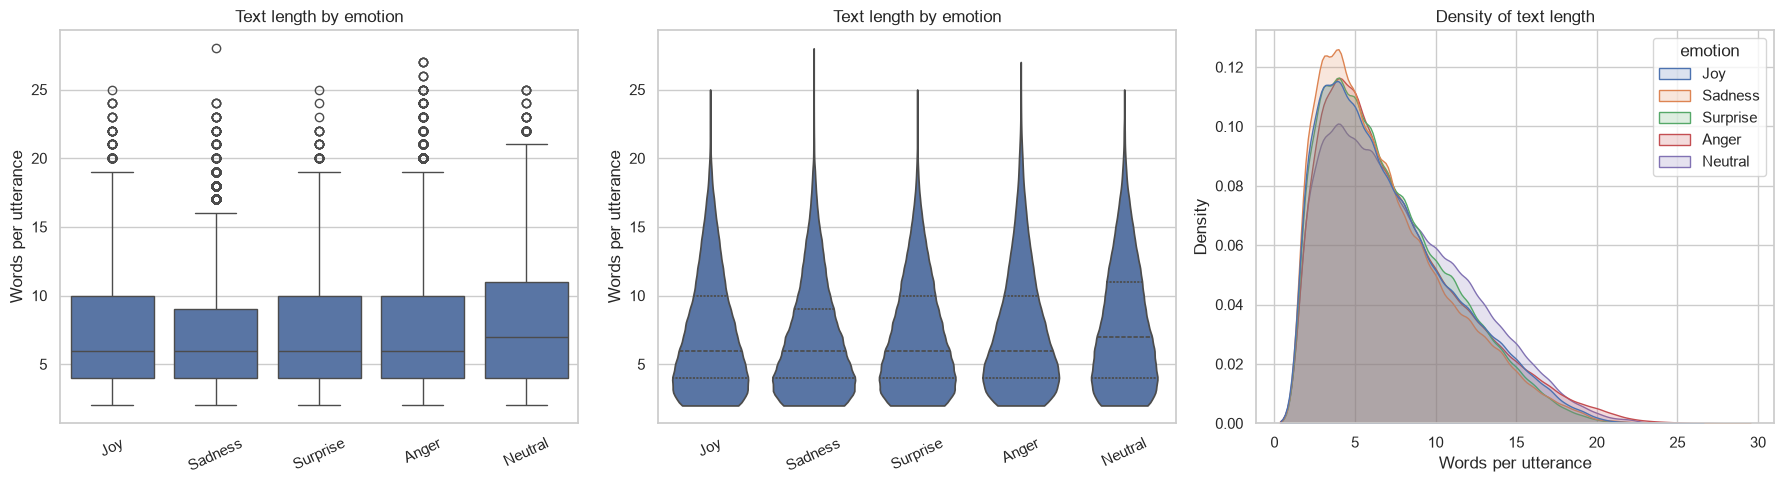

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(data=df, x="emotion", y="n_words", order=ORDER, ax=axes[0])
axes[0].set_title("Text length by emotion")

sns.violinplot(data=df, x="emotion", y="n_words", order=ORDER,
               cut=0, inner="quartile", ax=axes[1])
axes[1].set_title("Text length by emotion")

sns.kdeplot(data=df, x="n_words", hue="emotion", hue_order=ORDER,
            common_norm=False, fill=True, alpha=0.2, ax=axes[2])
axes[2].set_title("Density of text length")

for ax in axes[:2]:
    ax.set_xlabel("")
    ax.set_ylabel("Words per utterance")
    ax.tick_params(axis="x", rotation=25)
axes[2].set_xlabel("Words per utterance")

plt.tight_layout()
plt.show()

In [11]:
nlp = stanza.Pipeline("lt", processors="tokenize,pos,lemma",
                      use_gpu=False, verbose=False)

docs = nlp([stanza.Document([], text=t) for t in df["text"]])

try:
    import stopwordsiso
    STOP = set(stopwordsiso.stopwords("lt"))
except Exception:
    STOP = set()
STOP_UPOS = {"ADP", "CCONJ", "SCONJ", "PART", "PRON", "DET", "AUX", "INTJ"}

lemmas_per_text, pos_per_text = [], []
for doc in docs:
    lemmas, tags = [], []
    for sent in doc.sentences:
        for w in sent.words:
            if w.upos in {"PUNCT", "SYM", "X"} or not w.text.isalpha():
                continue
            tags.append(w.upos)                      # POS counts use all words
            lemma = (w.lemma or w.text).lower()
            if lemma in STOP or w.text in STOP or w.upos in STOP_UPOS or len(lemma) < 2:
                continue
            lemmas.append(lemma)                     # vocabulary: stop words removed
    lemmas_per_text.append(lemmas)
    pos_per_text.append(tags)

df["lemmas"] = lemmas_per_text
df["pos"] = pos_per_text
df[["text", "lemmas", "pos"]].head()

,text,lemmas,pos
0,džiugios naujienos iš čekijos,"[džiugis, naujiena, čekija]","[ADJ, NOUN, ADP, PROPN]"
1,sėkmė lydėjo mūsų mokyklos mokinį vilių,"[sėkmė, lydėti, mokykla, mokinys, vilis]","[NOUN, VERB, PRON, NOUN, NOUN, NOUN]"
2,čekijos sostinėje prahoje vykusiame tarptautin...,"[čekija, sostinė, praha, vykti, tarptautinis, ...","[PROPN, NOUN, PROPN, VERB, ADJ, ADJ, NOUN, NOUN]"
3,festivalyje laimėta pirmoji vieta,"[festivalis, laimėti, pirmas, vieta]","[NOUN, VERB, NUM, NOUN]"
4,didžiuojamės ir džiaugiamės įspūdingu pasiekim...,"[didžiuoti, džiaugti, įspūdingas, pasiekimas, ...","[VERB, CCONJ, VERB, ADJ, NOUN, CCONJ, VERB, PR..."


In [12]:
freqs = {
    e: Counter(l for ls in df.loc[df["emotion"] == e, "lemmas"] for l in ls)
    for e in ORDER
}

TOP_N = 15
top_table = pd.DataFrame({
    e: [f"{w} ({c})" for w, c in freqs[e].most_common(TOP_N)] for e in ORDER
})
top_table.index = range(1, TOP_N + 1)
top_table

,Joy,Sadness,Surprise,Anger,Neutral
1,džiaugsmas (1593),žmogus (1420),galėti (2414),čia (2086),galėti (1782)
2,diena (1158),labai (901),žmogus (1076),galėti (1138),turėti (1275)
3,labai (1158),galėti (884),taip (762),taip (985),žmogus (1240)
4,gyvenimas (1073),taip (723),čia (723),jau (965),miestas (1177)
5,galėti (883),gyvenimas (699),turėti (715),žmogus (881),daug (969)
6,geras (862),liūdesys (689),daug (715),kur (776),vilnius (900)
7,širdis (839),jau (667),neįtikėti (632),kodėl (773),metai (785)
8,naujas (818),turėti (616),metai (617),dabar (739),sakyti (778)
9,žmogus (812),daug (611),patikėti (614),norėti (708),lietuva (771)
10,atiti (803),liūdnas (577),įsivaizduoti (545),turėti (701),labai (751)


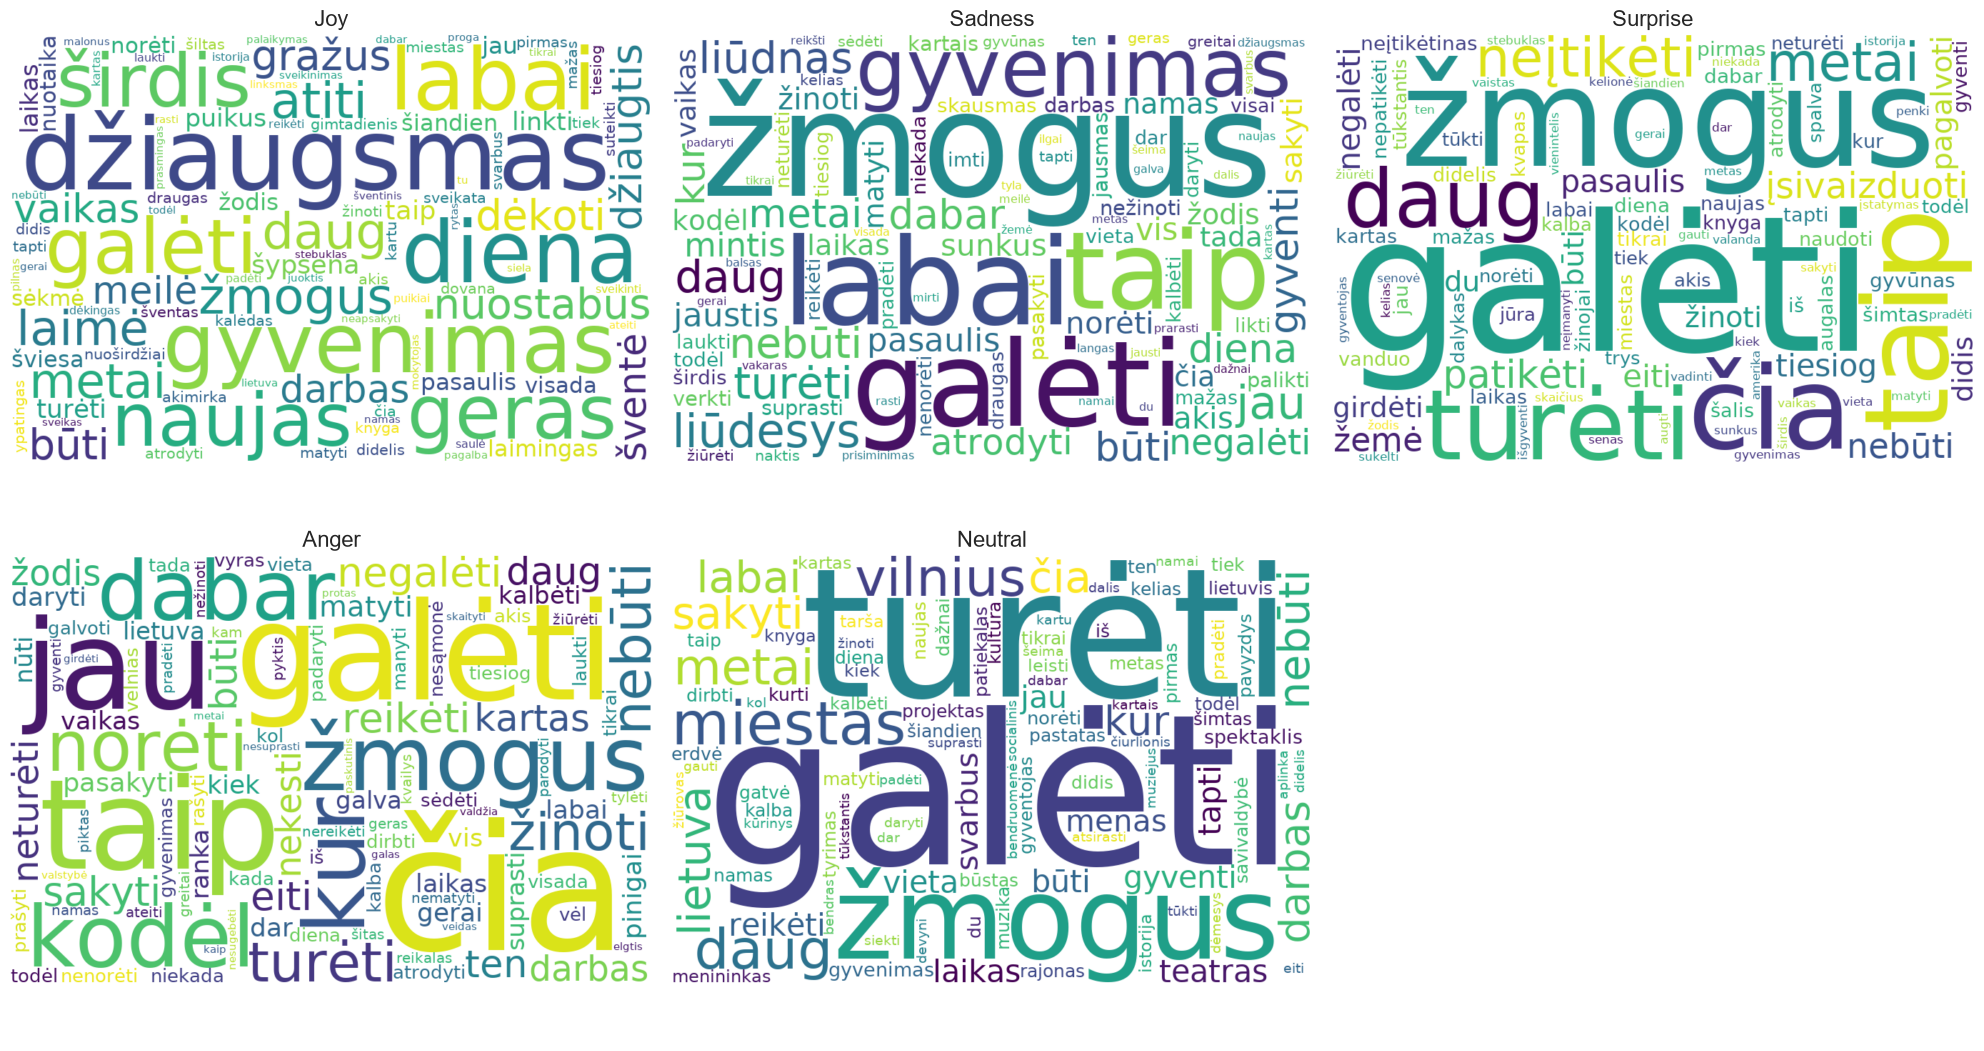

In [13]:
font_path = fm.findfont("DejaVu Sans")   # supports Lithuanian letters

fig, axes = plt.subplots(2, 3, figsize=(20, 11))
for ax, e in zip(axes.ravel(), ORDER):
    wc = WordCloud(width=900, height=600, background_color="white",
                   font_path=font_path, colormap="viridis",
                   max_words=100).generate_from_frequencies(freqs[e])
    ax.imshow(wc, interpolation="bilinear")
    ax.set_title(e, fontsize=16)
    ax.axis("off")
for ax in axes.ravel()[len(ORDER):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [17]:
pos_df = pd.DataFrame(
    [(e, t) for e, tags in zip(df["emotion"], df["pos"]) for t in tags],
    columns=["emotion", "upos"],
)

counts = pd.crosstab(pos_df["emotion"], pos_df["upos"]).loc[ORDER]
props = counts.div(counts.sum(axis=1), axis=0) * 100
props

upos,ADJ,ADP,ADV,AUX,CCONJ,DET,INTJ,NOUN,NUM,PART,PRON,PROPN,SCONJ,VERB
emotion,,,,,,,,,,,,,,
Joy,9.395342,4.428569,6.413692,1.748880,6.392164,5.132200,0.036824,31.487199,0.534805,3.105154,8.290041,0.726859,3.552146,18.756126
Sadness,5.844996,5.138819,8.031870,1.771834,5.433291,4.640438,0.068895,26.569732,0.681731,3.608119,9.602018,0.806743,4.407083,23.394432
Surprise,6.401916,4.760816,6.385066,2.126750,3.991117,4.341965,0.066198,31.061750,1.772292,3.823818,8.447424,1.944406,4.334744,20.541738
Anger,3.920260,4.921219,8.948300,0.986123,4.607183,5.009743,0.110778,20.991959,0.592960,4.832201,15.345737,0.913919,4.502339,24.317280
Neutral,7.341077,4.619352,6.597018,2.012815,5.041565,3.921029,0.022445,33.284068,1.416127,3.050771,5.443450,3.752483,3.262089,20.235711


# 3. Text Representation (Feature Extraction)

In [18]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from gensim.models import FastText
from sentence_transformers import SentenceTransformer

W1124 13:34:08.994000 13948 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


In [19]:
le = LabelEncoder()
y = le.fit_transform(df["emotion"])
print(dict(zip(le.classes_, range(len(le.classes_)))))

X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["text"].values, y,
    test_size=0.2,
    stratify=y,
    random_state=42,
)

print(len(X_train_text), len(X_test_text))
print("Train class share:", np.bincount(y_train) / len(y_train))
print("Test class share: ", np.bincount(y_test) / len(y_test))

{'Anger': 0, 'Joy': 1, 'Neutral': 2, 'Sadness': 3, 'Surprise': 4}
108171 27043
Train class share: [0.20754176 0.18565974 0.22912795 0.1980198  0.17965074]
Test class share:  [0.20752135 0.18566727 0.22915357 0.19801797 0.17963983]


In [20]:
tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True,
    lowercase=True,
    max_df=0.9,
)


X_train_tfidf = tfidf.fit_transform(X_train_text)
X_test_tfidf = tfidf.transform(X_test_text)

print("TF-IDF:", X_train_tfidf.shape, X_test_tfidf.shape)

TF-IDF: (108171, 125902) (27043, 125902)


In [21]:
train_tokens = [t.split() for t in X_train_text]
test_tokens = [t.split() for t in X_test_text]

# trained ONLY on the training texts
ft = FastText(
    sentences=train_tokens,
    vector_size=300,
    window=5,
    min_count=1,
    sg=1,            # skip-gram works better on small corpora
    min_n=2, max_n=5,
    epochs=30,
    seed=42,
    workers=4,
)

def doc_vector(tokens, model):
    """Mean of word vectors. FastText builds vectors for unseen words from subwords."""
    if not tokens:
        return np.zeros(model.vector_size)
    return np.mean([model.wv[w] for w in tokens], axis=0)

X_train_ft = np.vstack([doc_vector(t, ft) for t in train_tokens])
X_test_ft = np.vstack([doc_vector(t, ft) for t in test_tokens])

print("FastText:", X_train_ft.shape, X_test_ft.shape)

FastText: (108171, 300) (27043, 300)


In [22]:
sbert = SentenceTransformer("paraphrase-multilingual-mpnet-base-v2")  # supports Lithuanian

X_train_bert = sbert.encode(
    list(X_train_text), batch_size=64, show_progress_bar=True,
    convert_to_numpy=True,
)
X_test_bert = sbert.encode(
    list(X_test_text), batch_size=64, show_progress_bar=True,
    convert_to_numpy=True,
)

print("SBERT:", X_train_bert.shape, X_test_bert.shape)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Batches:   0%|          | 0/1691 [00:00<?, ?it/s]

Batches:   0%|          | 0/423 [00:00<?, ?it/s]

SBERT: (108171, 768) (27043, 768)


In [23]:
print(f"TF-IDF   : {X_train_tfidf.shape[1]} features (sparse)")
print(f"FastText : {X_train_ft.shape[1]} features (dense)")
print(f"SBERT    : {X_train_bert.shape[1]} features (dense)")

import scipy.sparse as sp
sp.save_npz("X_train_tfidf.npz", X_train_tfidf)
sp.save_npz("X_test_tfidf.npz", X_test_tfidf)
np.save("X_train_ft.npy", X_train_ft)
np.save("X_test_ft.npy", X_test_ft)
np.save("X_train_bert.npy", X_train_bert)
np.save("X_test_bert.npy", X_test_bert)
np.save("y_train.npy", y_train)
np.save("y_test.npy", y_test)

TF-IDF   : 125902 features (sparse)
FastText : 300 features (dense)
SBERT    : 768 features (dense)


# 4. Emotional Classification

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix,
)

sns.set_theme(style="white")
class_names = list(le.classes_)

In [25]:
datasets = {
    "TF-IDF":   (X_train_tfidf, X_test_tfidf),
    "FastText": (X_train_ft,    X_test_ft),
    "SBERT":    (X_train_bert,  X_test_bert),
}

def make_model(name):
    lr = LogisticRegression(max_iter=3000, C=1.0, random_state=42)
    if name == "TF-IDF":
        return lr                                   # TF-IDF is already normalized
    return make_pipeline(StandardScaler(), lr)      # scaler fitted on train only

models, preds = {}, {}
for name, (Xtr, Xte) in datasets.items():
    model = make_model(name)
    model.fit(Xtr, y_train)             # same y_train for all three
    models[name] = model
    preds[name] = model.predict(Xte)    # same y_test for all three
    print(f"{name}: trained")

TF-IDF: trained
FastText: trained
SBERT: trained


In [26]:
rows = []
for name, y_pred in preds.items():
    acc = accuracy_score(y_test, y_pred)
    p_m, r_m, f_m, _ = precision_recall_fscore_support(y_test, y_pred, average="macro", zero_division=0)
    p_w, r_w, f_w, _ = precision_recall_fscore_support(y_test, y_pred, average="weighted", zero_division=0)
    rows.append({
        "Model": name, "Accuracy": acc,
        "Precision (macro)": p_m, "Recall (macro)": r_m, "F1 (macro)": f_m,
        "Precision (weighted)": p_w, "Recall (weighted)": r_w, "F1 (weighted)": f_w,
    })

results = pd.DataFrame(rows).set_index("Model").round(4)
results

,Accuracy,Precision (macro),Recall (macro),F1 (macro),Precision (weighted),Recall (weighted),F1 (weighted)
Model,,,,,,,
TF-IDF,0.9172,0.9189,0.9153,0.9167,0.9178,0.9172,0.9171
FastText,0.6468,0.6460,0.6424,0.6430,0.6464,0.6468,0.6455
SBERT,0.6798,0.6809,0.6761,0.6772,0.6806,0.6798,0.6789


In [27]:
for name, y_pred in preds.items():
    print(f"\n===== {name} =====")
    print(classification_report(y_test, y_pred, target_names=class_names, digits=3, zero_division=0))


===== TF-IDF =====
              precision    recall  f1-score   support

       Anger      0.900     0.937     0.918      5612
         Joy      0.938     0.901     0.919      5021
     Neutral      0.909     0.945     0.927      6197
     Sadness      0.907     0.908     0.907      5355
    Surprise      0.941     0.886     0.913      4858

    accuracy                          0.917     27043
   macro avg      0.919     0.915     0.917     27043
weighted avg      0.918     0.917     0.917     27043


===== FastText =====
              precision    recall  f1-score   support

       Anger      0.652     0.724     0.686      5612
         Joy      0.707     0.653     0.679      5021
     Neutral      0.670     0.715     0.692      6197
     Sadness      0.575     0.559     0.567      5355
    Surprise      0.626     0.560     0.591      4858

    accuracy                          0.647     27043
   macro avg      0.646     0.642     0.643     27043
weighted avg      0.646     0.647  

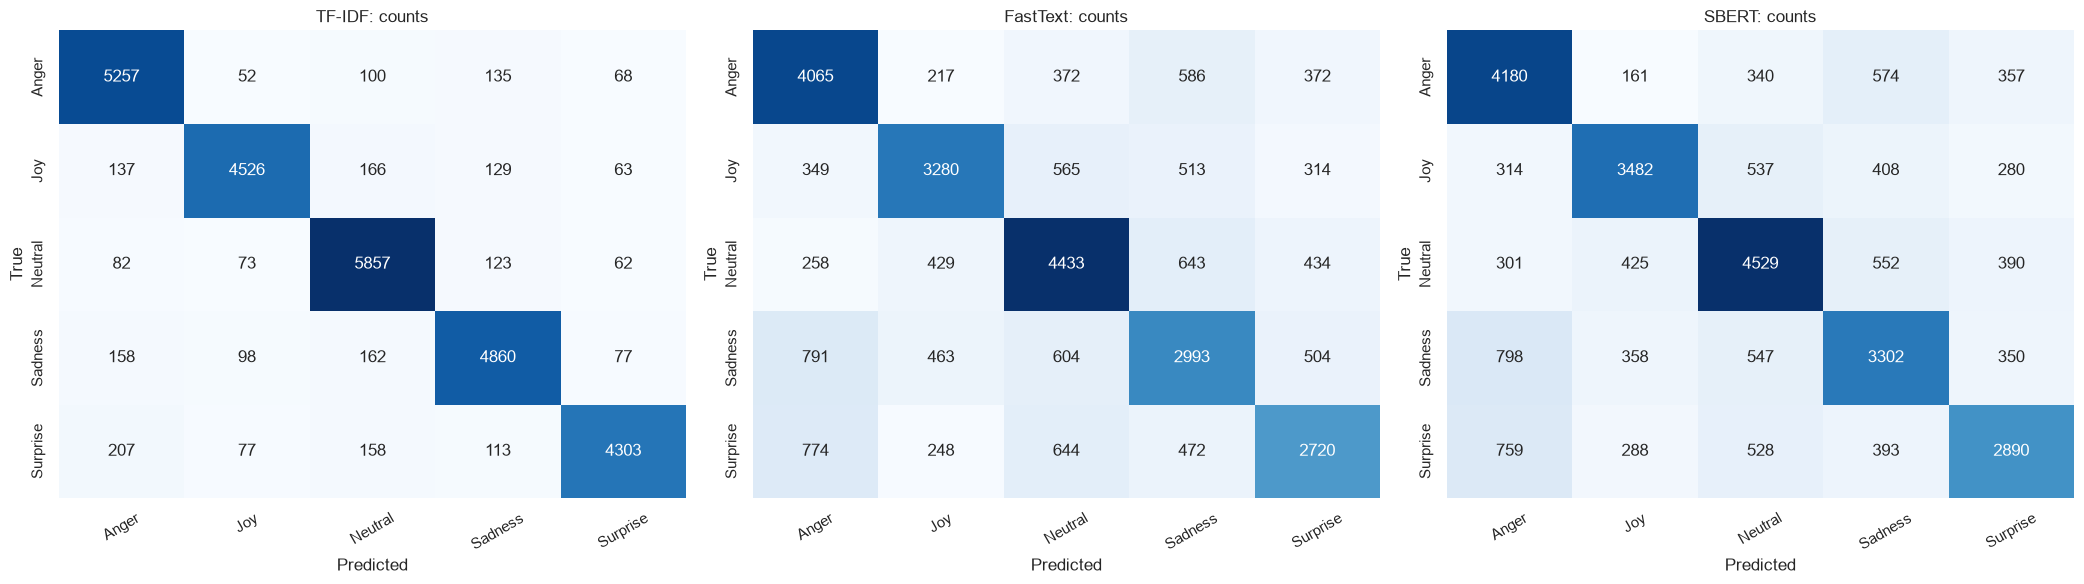

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(21, 6))

for j, (name, y_pred) in enumerate(preds.items()):
    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=class_names,
        yticklabels=class_names,
        ax=axes[j]
    )

    axes[j].set_title(f"{name}: counts")
    axes[j].set_xlabel("Predicted")
    axes[j].set_ylabel("True")
    axes[j].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()